In [1]:
# pip install nb_black==1.0.5
%load_ext lab_black

In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt


pd.options.display.max_columns = None
pd.options.display.max_rows = None
pd.set_option("display.float_format", "{:,.2f}".format)

In [26]:
# dir = "../src/data_science_candidate_takehome"
# file = "data.csv"
# path = os.path.join(dir, file)
# df = pd.read_csv(path)
train = pd.read_csv("../train_data.csv").assign(split="Train")
test = pd.read_csv("../test_data.csv").assign(split="Test")

# Quick Summary

- **Data quality:** No missing values or duplicates in either train or test sets
- **Covariate balance:** Treatment and control groups are well-balanced across features (SMD < 0.1 for 13/14 feature-split combinations). Only `customer_tenure_days` shows minor imbalance in test set (SMD = -0.11)
- **Target distribution:** `total_30d_post_campaign_spend` exhibits heavy-tailed behavior with many low/zero values and a few extreme high-spenders ("whales"). This right-skewed distribution poses modeling challenges:
  - Models minimizing squared error will likely underpredict the tail
  - Campaign-level aggregations are sensitive to these rare high-spenders
  - Log transformation considered to stabilize variance
- **Feature distributions:** Numeric features show consistent distributions across splits with no concerning skewness. Minor distributional shifts in `customer_tenure_days` and `email_open_rate` in test set are within acceptable ranges
- **Implications for modeling:** The well-balanced treatment assignment supports causal inference, but the heavy-tailed outcome requires careful handling (log transformation, robust loss functions, or ensemble methods)

## Quick Peep and Check For NA

In [10]:
train.head()

,customer_id,campaign_id,campaign_send_date,treatment_group,historical_lifetime_spend,brand_affinity_score,web_activity_score,days_since_last_purchase,price_sensitivity,email_open_rate,customer_tenure_days,total_30d_post_campaign_spend
0,9c82b24c287722c266a270f3885e1d31,5509bdbde8a099bb0e90da038bebc5dc,2024-10-01,1,488.92,0.37,51.33,7.31,0.97,0.39,1382,0.00
1,d2ed2bc885c4a07980d80e740830fc38,bebd4330cebc8828cae556381461f7fd,2025-01-01,0,"3,119.02",0.18,52.15,2.68,0.31,0.29,719,"6,720.14"
2,3200b5b071620924d708b8a910e983f6,5509bdbde8a099bb0e90da038bebc5dc,2024-10-01,1,"2,437.23",0.53,49.73,56.64,0.94,0.78,943,"1,601.21"
3,31fb38090ded6a286e6a932fcccff107,4a9e47415d6a1dfc7010ea395ed044ae,2024-07-01,1,"1,399.80",0.07,53.16,27.54,0.86,0.20,874,"1,245.40"
4,b861e15e937cfae1ceac152b1c4a8dc1,4a9e47415d6a1dfc7010ea395ed044ae,2024-07-01,1,294.92,0.70,47.26,151.41,0.73,0.26,192,367.62


In [11]:
test.head()

,customer_id,campaign_id,campaign_send_date,treatment_group,historical_lifetime_spend,brand_affinity_score,web_activity_score,days_since_last_purchase,price_sensitivity,email_open_rate,customer_tenure_days,total_30d_post_campaign_spend
0,9a498078f9fe0ee6a6cafecd1b446456,79a19a445f972356e38aee7c6515474a,2026-12-01,1,"1,343.82",0.33,54.69,87.98,0.61,0.35,505,"1,345.18"
1,142aa2cca99333e5c52e750e5fe63b02,f67979d7ab411ec44f296ca398c025c1,2025-09-01,1,441.79,0.37,53.84,139.05,0.75,0.88,254,0.00
2,88f257c4291c07b5af86c291b568b0cf,f67979d7ab411ec44f296ca398c025c1,2025-09-01,1,996.12,0.35,53.78,72.86,0.62,0.91,810,"1,731.06"
3,39206b9a0b6f470570b6d22c4efa149d,f67979d7ab411ec44f296ca398c025c1,2025-09-01,1,939.99,0.08,51.57,122.20,0.70,0.82,1889,"1,149.70"
4,663649ed5b9b63aa94d3ed69c07b0025,f67979d7ab411ec44f296ca398c025c1,2025-09-01,1,"1,078.30",0.36,48.92,23.54,0.71,0.90,1161,245.22


There is no missing values in the dataframe.

In [8]:
train.isna().sum()

customer_id                      0
campaign_id                      0
campaign_send_date               0
treatment_group                  0
historical_lifetime_spend        0
brand_affinity_score             0
web_activity_score               0
days_since_last_purchase         0
price_sensitivity                0
email_open_rate                  0
customer_tenure_days             0
total_30d_post_campaign_spend    0
dtype: int64

In [9]:
test.isna().sum()

customer_id                      0
campaign_id                      0
campaign_send_date               0
treatment_group                  0
historical_lifetime_spend        0
brand_affinity_score             0
web_activity_score               0
days_since_last_purchase         0
price_sensitivity                0
email_open_rate                  0
customer_tenure_days             0
total_30d_post_campaign_spend    0
dtype: int64

Notice the number of unique users matches the row count. There are no duplicate rows in the dataframe. **However**, there is a near 5 to 1 ratio between the treatment and the control group. The ratio is similar between the training and testing set.

In [14]:
train.groupby("treatment_group", as_index=False, dropna=False).agg(
    user_cnt=("customer_id", "nunique")
)

,treatment_group,user_cnt
0,0,1960
1,1,10077


In [19]:
10077 / 1960

5.141326530612245

In [13]:
train.shape

(12037, 12)

In [17]:
test.groupby("treatment_group", as_index=False, dropna=False).agg(
    user_cnt=("customer_id", "nunique")
)

,treatment_group,user_cnt
0,0,517
1,1,2446


In [18]:
2446 / 517

4.731141199226306

Test set's campaigns happen after the training set. There are no overlap between the campaigns. We can use campaign_send_date to derive seasonality factor for the model.

In [30]:
df_all = pd.concat([train, test], ignore_index=True)
df_all.groupby(["split", "campaign_id", "campaign_send_date"], as_index=False).agg(
    row_cnt=("customer_id", "count")
)

,split,campaign_id,campaign_send_date,row_cnt
0,Test,6349d955e0d37075d3cb5e97afc43707,2025-11-01,745
1,Test,79a19a445f972356e38aee7c6515474a,2026-12-01,755
2,Test,f67979d7ab411ec44f296ca398c025c1,2025-09-01,1463
3,Train,4a9e47415d6a1dfc7010ea395ed044ae,2024-07-01,5159
4,Train,5509bdbde8a099bb0e90da038bebc5dc,2024-10-01,3755
5,Train,bebd4330cebc8828cae556381461f7fd,2025-01-01,3123


## Distribution Difference Between Train/Test Set and Control/Treatment Set

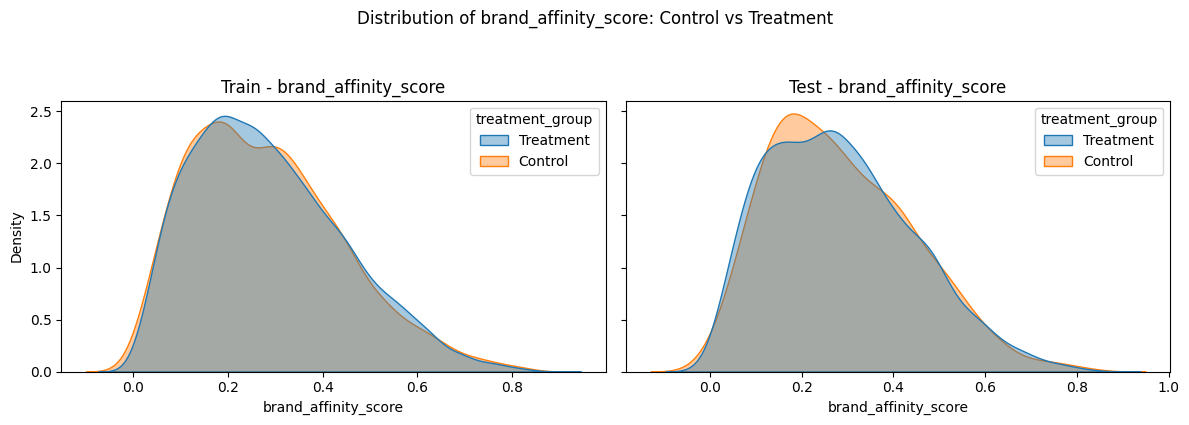

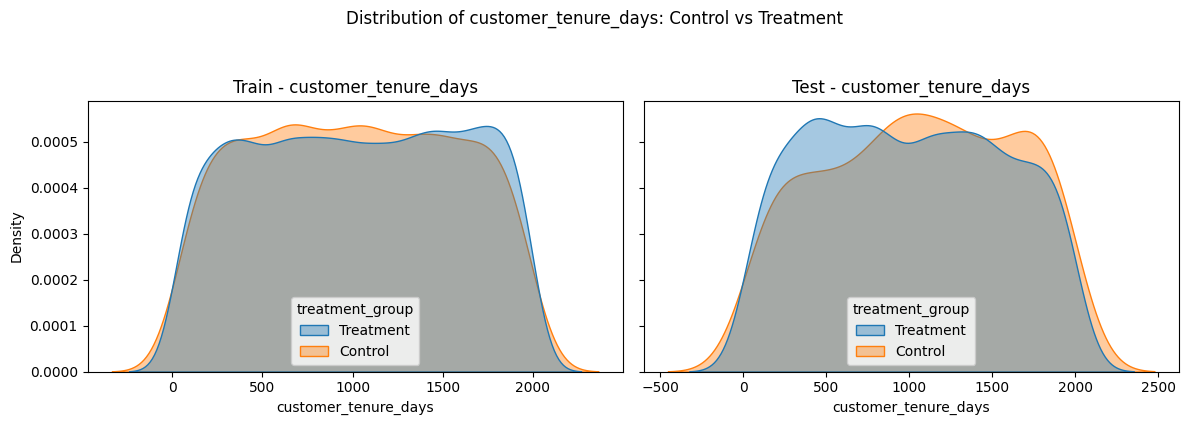

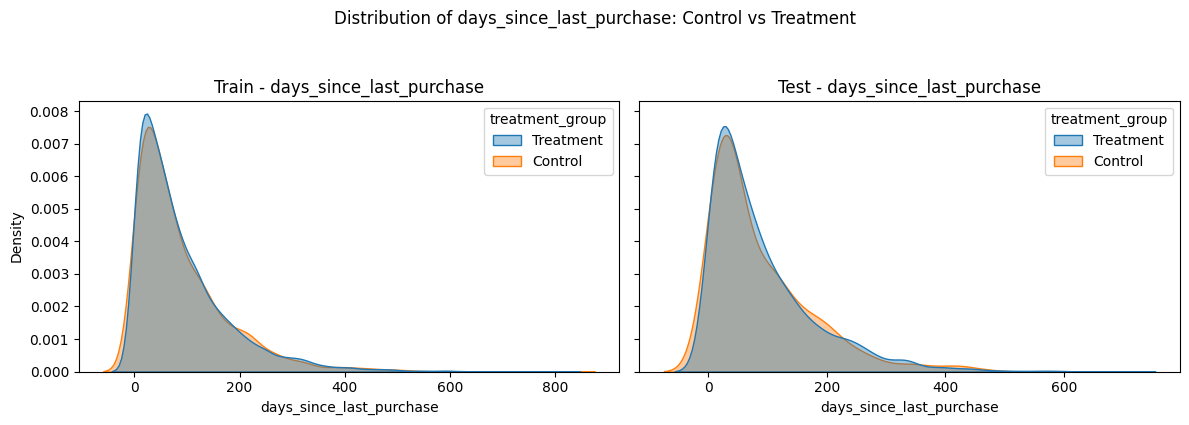

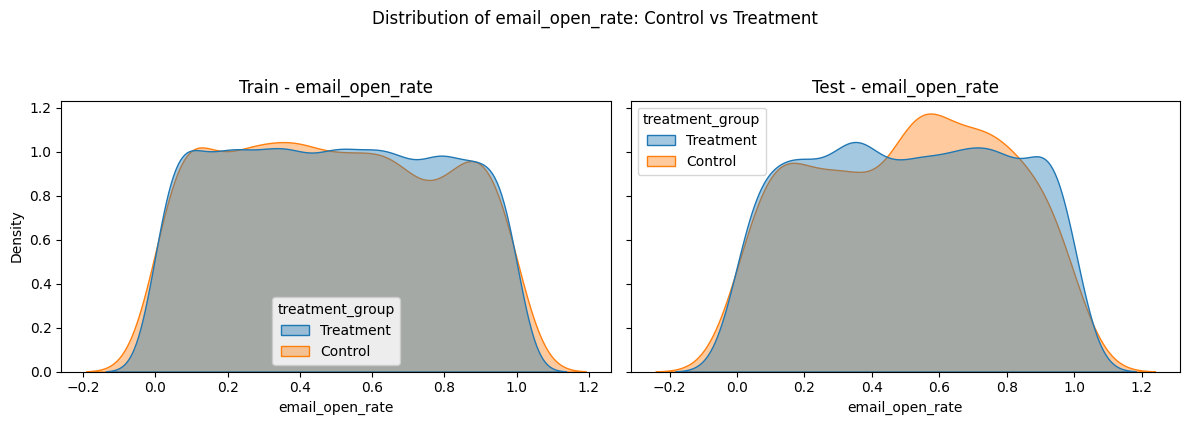

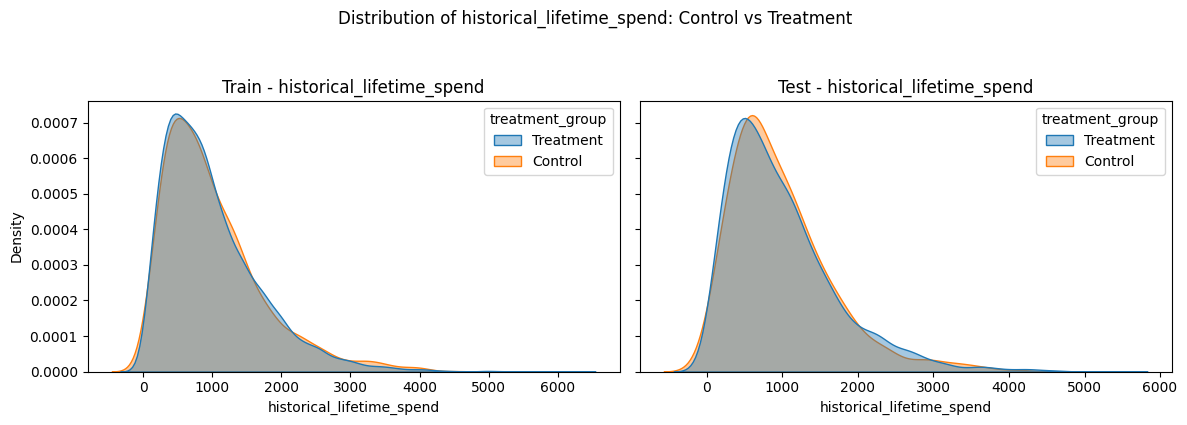

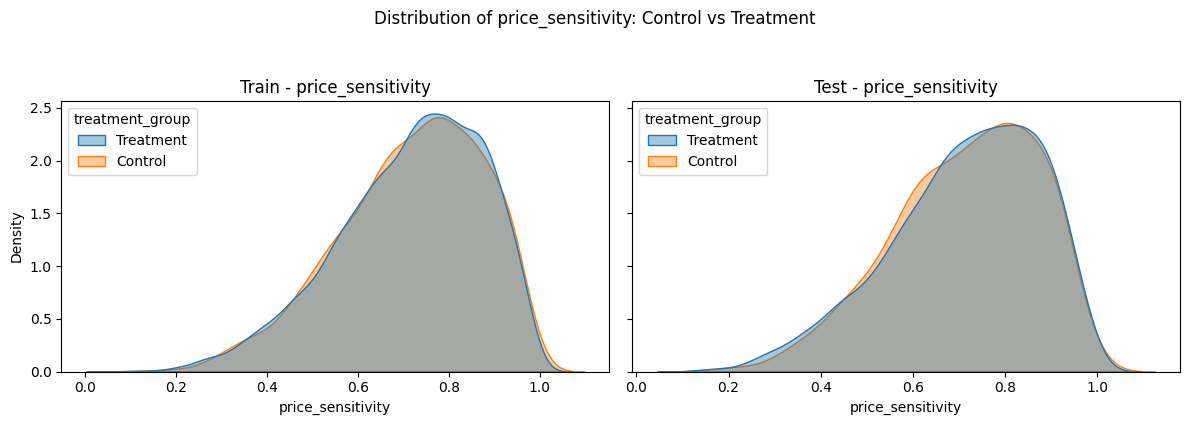

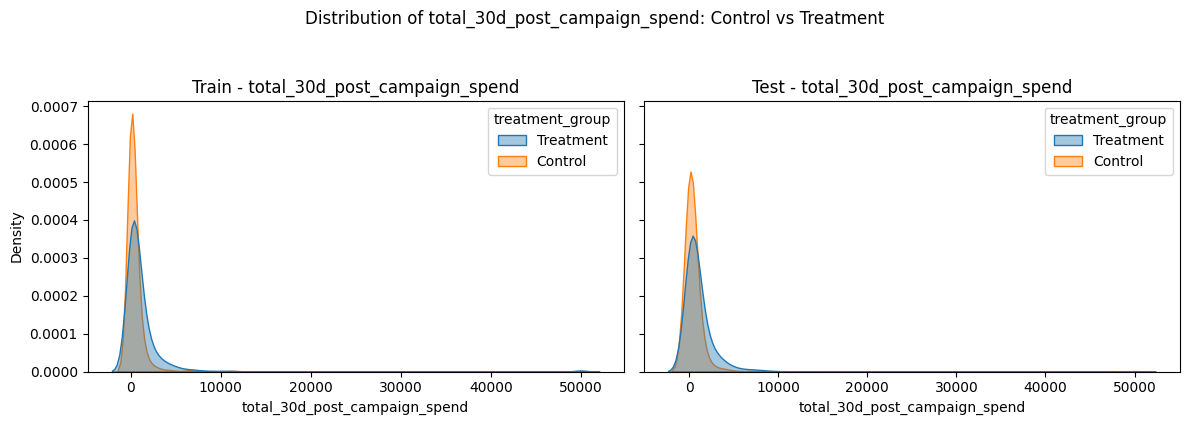

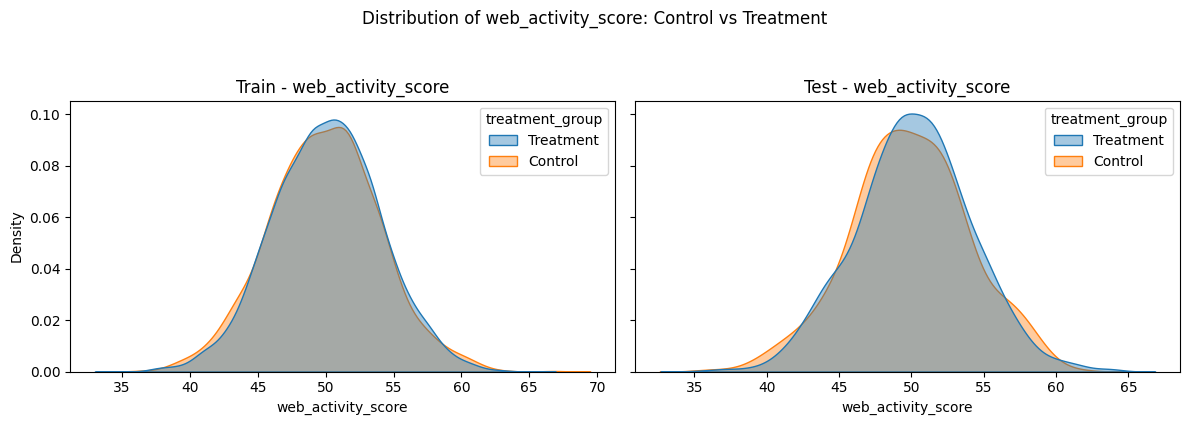

In [31]:
df_all["treatment_group"] = df_all["treatment_group"].map(
    {0: "Control", 1: "Treatment"}
)

exclude = [
    "campaign_id",
    "treatment_group",
]  # "total_30d_post_campaign_spend"
num_features = df_all.select_dtypes(include="number").columns.difference(exclude)

for feat in num_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    # Train
    sns.kdeplot(
        data=df_all[df_all.split == "Train"],
        x=feat,
        hue="treatment_group",
        fill=True,
        alpha=0.4,
        common_norm=False,
        ax=axes[0],
    )
    axes[0].set_title(f"Train - {feat}")

    # Test
    sns.kdeplot(
        data=df_all[df_all.split == "Test"],
        x=feat,
        hue="treatment_group",
        fill=True,
        alpha=0.4,
        common_norm=False,
        ax=axes[1],
    )
    axes[1].set_title(f"Test - {feat}")

    plt.suptitle(f"Distribution of {feat}: Control vs Treatment", y=1.05)
    plt.tight_layout()
    plt.show()

In [32]:
df_all.treatment_group.value_counts()

treatment_group
Treatment    12523
Control       2477
Name: count, dtype: int64

### SMD (Standardize Mean Difference) Check
- Overall control and treatment group are very well balance, suggesting a near perfect random assignment;
- Only 1 minor imbalance in `customer_tenure_days`, but it is slightly over threshold. It is not likely to impact subsequent model performance.

In [33]:
# --- choose numeric features (exclude ids/target/group) --
exclude = {"treatment_group", "total_30d_post_campaign_spend", "campaign_id"}
num_features = [
    c for c in df_all.select_dtypes(include=[np.number]).columns if c not in exclude
]

if not num_features:
    raise RuntimeError(
        "No numeric features found after exclusions. Check column names and dtypes."
    )


def pooled_sd(a, b):
    return np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2.0)


results = []

for split_name, df_split in df_all.groupby("split"):
    # counts sanity check
    n_treat = (df_split["treatment_group"] == "Treatment").sum()
    n_ctrl = (df_split["treatment_group"] == "Control").sum()
    print(f"[{split_name}] n_treat={n_treat}, n_ctrl={n_ctrl}")

    for feat in num_features:
        treat = df_split.loc[df_split.treatment_group == "Treatment", feat].dropna()
        ctrl = df_split.loc[df_split.treatment_group == "Control", feat].dropna()
        if (
            len(treat) > 1
            and len(ctrl) > 1
            and treat.var(ddof=1) >= 0
            and ctrl.var(ddof=1) >= 0
        ):
            sd = pooled_sd(treat.values, ctrl.values)
            # Guard against zero variance
            smd = (treat.mean() - ctrl.mean()) / sd if sd > 0 else 0.0
            results.append({"split": split_name, "feature": feat, "smd": smd})

smd_df = pd.DataFrame(results)

if smd_df.empty:
    print(
        "No SMD rows produced. Likely causes: no overlap, no numeric features, or all-zero variance."
    )
else:
    smd_df["abs_smd"] = smd_df["smd"].abs()
    smd_df["imbalance_flag"] = smd_df["abs_smd"] > 0.1
    smd_df = smd_df.sort_values("abs_smd", ascending=False)

[Test] n_treat=2446, n_ctrl=517
[Train] n_treat=10077, n_ctrl=1960


In [34]:
smd_df

,split,feature,smd,abs_smd,imbalance_flag
6,Test,customer_tenure_days,-0.11,0.11,True
2,Test,web_activity_score,0.06,0.06,False
9,Train,web_activity_score,0.04,0.04,False
3,Test,days_since_last_purchase,0.03,0.03,False
7,Train,historical_lifetime_spend,-0.03,0.03,False
13,Train,customer_tenure_days,0.03,0.03,False
8,Train,brand_affinity_score,0.02,0.02,False
10,Train,days_since_last_purchase,0.02,0.02,False
12,Train,email_open_rate,0.02,0.02,False
0,Test,historical_lifetime_spend,0.01,0.01,False
